# Comparing AIvory vs Gemini/Claude/OpenAI Results

This notebook runs the AIvory classic image segmentation approach alongside agentic LLM-based
classifiers on public-domain ivory and bone images, comparing predictions side by side.

## 1. Imports & Environment Setup

In [1]:
import os
import io
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Add the ivory_repo source package to the path
sys.path.insert(0, str(Path('../src').resolve()))

# fastai utilities
from fastai.data.transforms import get_image_files

# ivory_repo: ML model loader
from ivory_repo.ml import load_model

# ivory_repo: LLM helpers (client initialisation + JSON extractor)
from ivory_repo.llm import init_gemini_client, extract_json

## 2. API Keys & Client Configuration

Set your API keys as environment variables before initialising the clients.
Replace the placeholder strings (or, better, export them in your shell before launching Jupyter).

In [ ]:
# Set API keys (replace with your own, or export in your shell beforehand)
os.environ["GOOGLE_API_KEY"]    = "..."
os.environ["ANTHROPIC_API_KEY"] = "..."

# Initialise Gemini client
gemini_client = init_gemini_client()
model_id = "gemini-2.5-pro"

## 3. Data & Model Paths

In [3]:
# Root Ivory dataset path (training data + saved model weights live here)
path     = Path("/mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/")
path_lbl = path / "binary_masks_new"

# Public-domain test images
base_public = path / "Public_domain_ivory_bone_images"

test_path_ivory = base_public / "ivory_gemini"
test_path_bone  = base_public / "bone_gemini"

# Output directory for comparison CSVs
outpath = base_public / "inference_gemini"
outpath.mkdir(parents=True, exist_ok=True)

print("Paths configured:")
print(f"  Training/model root : {path}")
print(f"  Ivory test images   : {test_path_ivory}")
print(f"  Bone test images    : {test_path_bone}")
print(f"  Output directory    : {outpath}")

Paths configured:
  Training/model root : /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory
  Ivory test images   : /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/ivory_gemini
  Bone test images    : /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/bone_gemini
  Output directory    : /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/inference_gemini


## 4. Helper Functions

In [4]:
def classic_predict_from_pred(pred, thr=0.3):
    """
    Convert a fastai segmentation prediction tensor into a classification result.

    pred shape: [n_classes, H, W]
    Classes: 0 = background | 1 = ivory | 2 = bone
    """
    if hasattr(pred, "detach"):
        pred = pred.detach().cpu().numpy()

    pred_arx = pred.argmax(axis=0)

    ivory = np.where(pred_arx > 0, pred[1], np.nan)
    bone  = np.where(pred_arx > 0, pred[2], np.nan)

    denom = ivory + bone
    excess = np.where(
        np.isfinite(denom) & (denom != 0),
        (ivory - bone) / denom,
        np.nan,
    )

    flat = excess[~np.isnan(excess)]

    if flat.size == 0:
        return {"ivory_frac": np.nan, "avg_pred": np.nan,
                "class": "uncertain", "excess": excess}

    ivory_frac = float(np.mean(flat > 0))
    avg_pred   = float(np.mean(flat))

    if avg_pred > thr:
        klass = "ivory"
    elif avg_pred < -thr:
        klass = "bone"
    else:
        klass = "uncertain"

    return {"ivory_frac": ivory_frac, "avg_pred": avg_pred,
            "class": klass, "excess": excess}

In [5]:
def gemini_classify_image(client, model_id, image_path):
    """Send a single image to Gemini for forensic ivory/bone classification."""

    image_to_analyze = Image.open(image_path).convert("RGB")

    buf = io.BytesIO()
    image_to_analyze.save(buf, format="JPEG")
    image_bytes = buf.getvalue()

    prompt = """
You are analyzing carved objects for forensic ivory identification.

Your task is NOT to guess based on object type.

Instead, analyze ONLY visible material evidence.

Look carefully for:

IVORY indicators:
- Schreger lines
- smooth dense texture
- subtle crosshatching
- semi-translucence
- consistent creamy coloration

BONE indicators:
- visible pores or vascular canals
- grainy structure
- dot-like pits
- porous texture
- irregular internal structure

If the material evidence is insufficient, answer "uncertain".

Return ONLY valid JSON:

{
  "class": "ivory|bone|uncertain",
  "confidence": 0.0,
  "reasoning": "short explanation referencing visible evidence"
}
"""

    response = client.models.generate_content(
        model=model_id,
        contents=[
            {
                "parts": [
                    {"inline_data": {"mime_type": "image/jpeg", "data": image_bytes}},
                    {"text": prompt},
                ]
            }
        ],
    )

    raw_text = response.text.strip()
    parsed   = extract_json(raw_text)

    if parsed is None:
        return {"class": "uncertain", "confidence": None,
                "reasoning": "Could not parse Gemini JSON response.",
                "raw_text": raw_text}

    return {
        "class":      str(parsed.get("class", "uncertain")).strip().lower(),
        "confidence": parsed.get("confidence", None),
        "reasoning":  str(parsed.get("reasoning", "")).strip(),
        "raw_text":   raw_text,
    }

In [ ]:
def compare_classic_vs_gemini(
    learn,
    client,
    model_id,
    image_paths,
    thr=0.3,
    show_examples=False,
):
    """Run AIvory segmentation model and an LLM classifier on the same images
    and return a DataFrame comparing their predictions."""

    results = []

    for i, image_path in enumerate(image_paths):

        image_path = Path(image_path)
        print(f"Processing {i+1}/{len(image_paths)}: {image_path.name}")

        # ── Classic segmentation model ────────────────────────────────────
        try:
            dl    = learn.dls.test_dl([image_path])
            preds = learn.get_preds(dl=dl)
            classic_pred = classic_predict_from_pred(preds[0][0], thr=thr)
        except Exception as e:
            print(f"  Classic model failed: {e}")
            classic_pred = {"class": "error", "ivory_frac": np.nan,
                            "avg_pred": np.nan, "excess": None}

        # ── Gemini ────────────────────────────────────────────────────────
        try:
            gemini_pred = gemini_classify_image(client, model_id, image_path)
        except Exception as e:
            print(f"  Gemini failed: {e}")
            gemini_pred = {"class": "error", "confidence": None,
                           "reasoning": str(e), "raw_text": ""}

        # ── Collect results ───────────────────────────────────────────────
        row = {
            "filename":           image_path.name,
            "path":               str(image_path),
            # Classic model
            "classic_class":      classic_pred["class"],
            "classic_ivory_frac": classic_pred["ivory_frac"],
            "classic_avg_pred":   classic_pred["avg_pred"],
            # Gemini
            "gemini_class":       gemini_pred["class"],
            "gemini_confidence":  gemini_pred["confidence"],
            "gemini_reasoning":   gemini_pred["reasoning"],
            "gemini_raw_text":    gemini_pred["raw_text"],
        }
        results.append(row)

        # ── Optional per-image visualisation ─────────────────────────────
        if show_examples:
            img = Image.open(image_path).convert("RGB")
            plt.figure(figsize=(6, 6))
            plt.imshow(img)
            plt.title(
                f"{image_path.name}\n"
                f"Classic: {classic_pred['class']} | "
                f"Gemini: {gemini_pred['class']}"
            )
            plt.axis("off")
            plt.show()

    return pd.DataFrame(results)

## 5. Load the Segmentation Model

Model index 3 corresponds to `justbones_rrc_aug_huesat_bs8_stage2_new`.
The weights are loaded from `path/models/` automatically by fastai.

In [7]:
learn = load_model(model_index=3, train_path=path, path_lbl=path_lbl)

---
## 6. Comparing AIvory vs Gemini Results

### Ivory

Running comparison on 15 ivory images...
Processing 1/15: image_1.jpeg


/home/axt807/miniconda3/envs/ivory_project/lib/python3.10/site-packages/fastai/metrics.py:375: RuntimeWarning: Mean of empty slice
  return np.nanmean(binary_dice_scores)


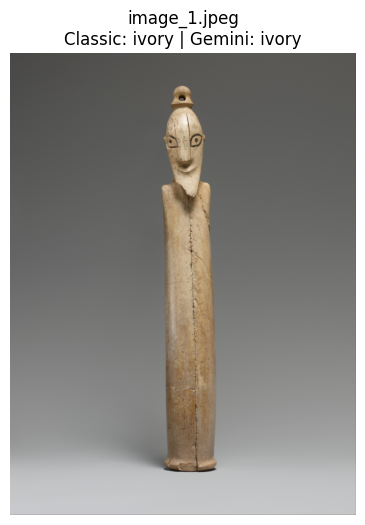

Processing 2/15: image_10.jpeg


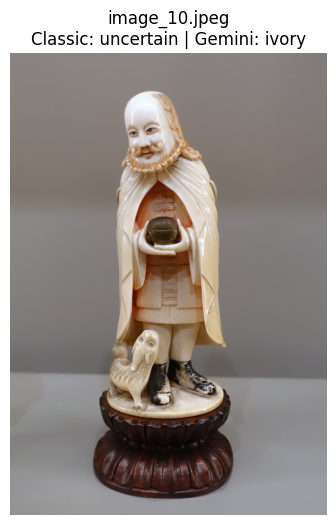

Processing 3/15: image_11.jpg


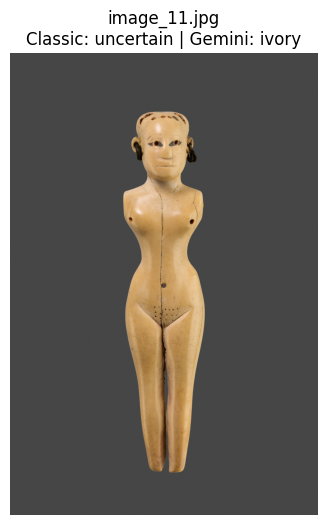

Processing 4/15: image_12.jpeg


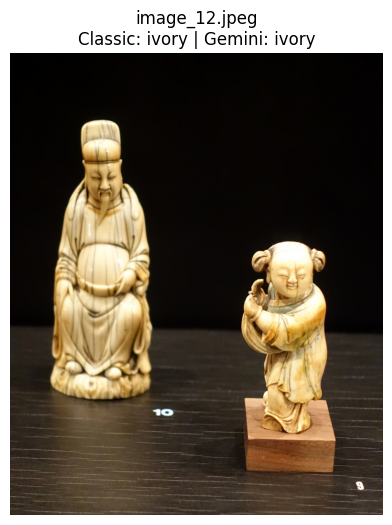

Processing 5/15: image_13.jpeg


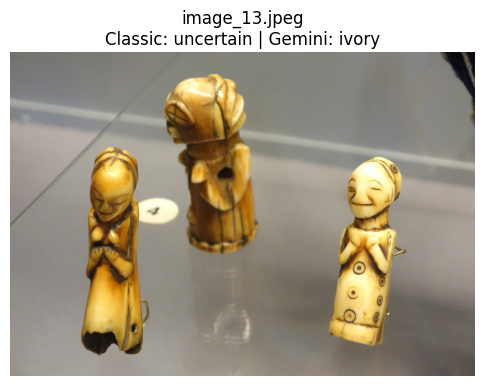

Processing 6/15: image_14.jpeg


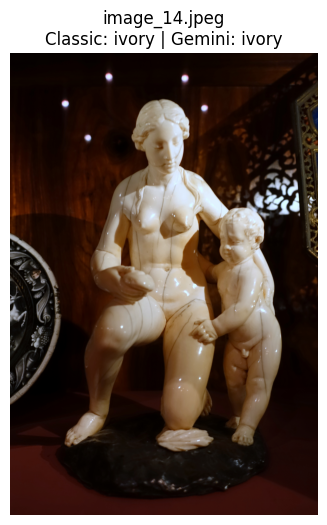

Processing 7/15: image_15.jpeg


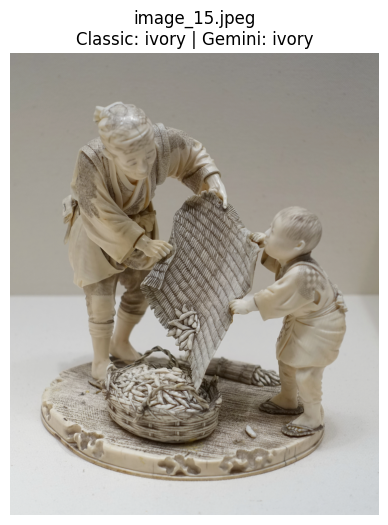

Processing 8/15: image_16.jpeg


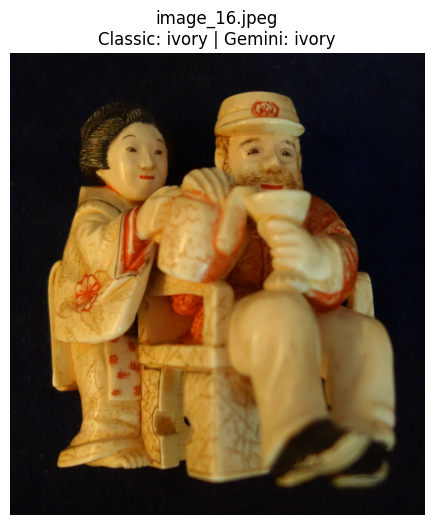

Processing 9/15: image_17.jpg


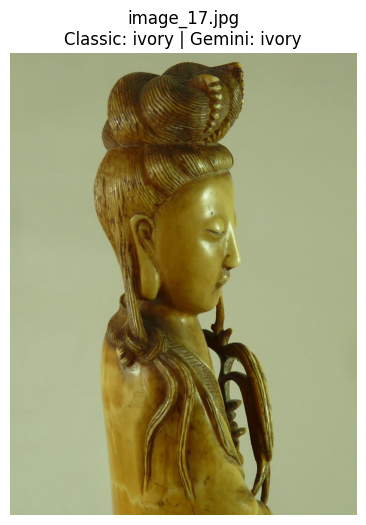

Processing 10/15: image_18.jpg


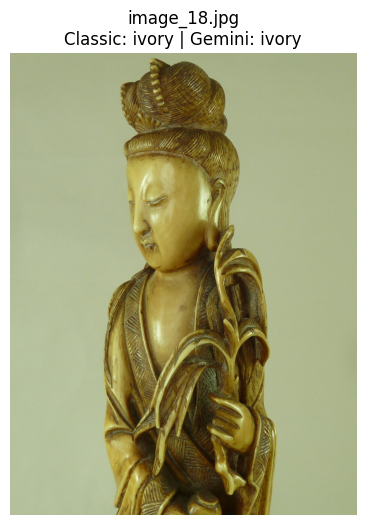

Processing 11/15: image_19.jpg


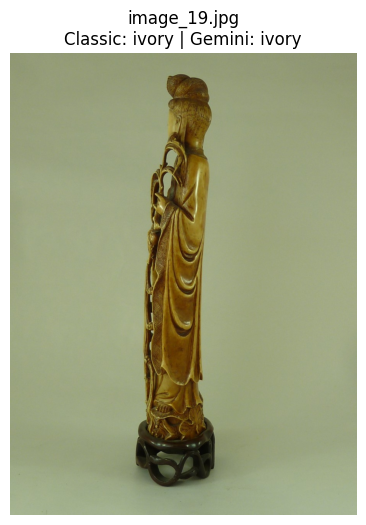

Processing 12/15: image_2.jpeg


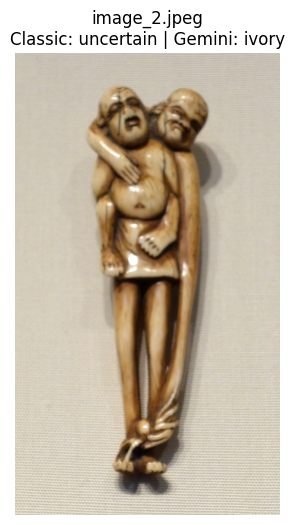

Processing 13/15: image_20.jpg


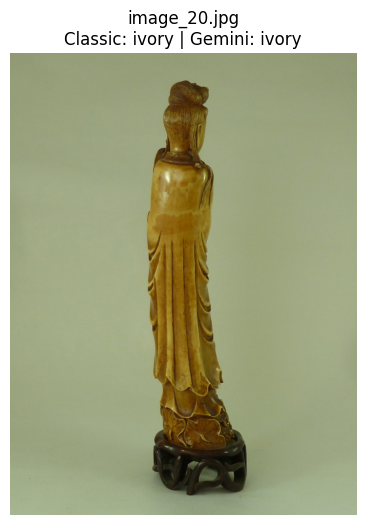

Processing 14/15: image_21.jpg


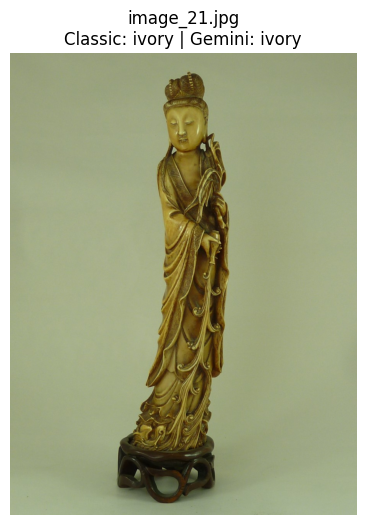

Processing 15/15: image_22.jpeg


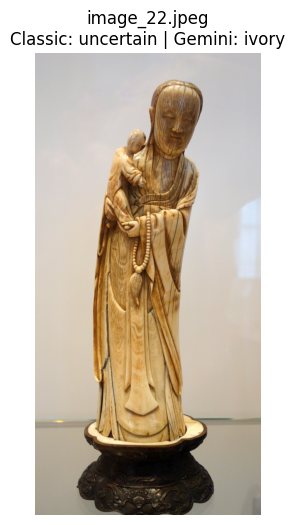

        filename  \
0   image_1.jpeg   
1  image_10.jpeg   
2   image_11.jpg   
3  image_12.jpeg   
4  image_13.jpeg   

                                                                                                              path  \
0   /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/ivory_gemini/image_1.jpeg   
1  /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/ivory_gemini/image_10.jpeg   
2   /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/ivory_gemini/image_11.jpg   
3  /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/ivory_gemini/image_12.jpeg   
4  /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/ivory_gemini/image_13.jpeg   

  classic_class  classic_ivory_frac  classic_avg_pred gemini_class  \
0         ivory            0.904188          0.717136        ivory   
1     uncertain            0.4

In [8]:
# Collect ivory test images
image_files_ivory = get_image_files(test_path_ivory)
image_files_ivory = image_files_ivory[:15]   # limit for a quick run

print(f"Running comparison on {len(image_files_ivory)} ivory images...")

comparison_df_ivory = compare_classic_vs_gemini(
    learn=learn,
    client=gemini_client,
    model_id=model_id,
    image_paths=image_files_ivory,
    thr=0.3,
    show_examples=True,
)

ivory_csv = outpath / "classic_vs_gemini_ivory_comparison.csv"
comparison_df_ivory.to_csv(ivory_csv, index=False)

print(comparison_df_ivory.head())
print(f"\nSaved comparison to:\n{ivory_csv}")

### Bone

Running comparison on 15 bone images...
Processing 1/15: image_1.jpeg


/home/axt807/miniconda3/envs/ivory_project/lib/python3.10/site-packages/fastai/metrics.py:375: RuntimeWarning: Mean of empty slice
  return np.nanmean(binary_dice_scores)


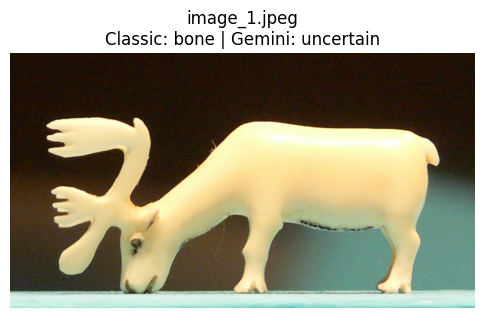

Processing 2/15: image_10.jpeg


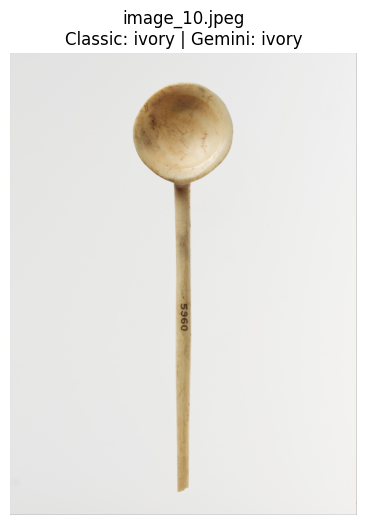

Processing 3/15: image_11.jpeg


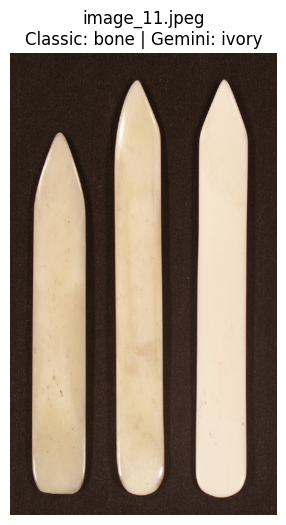

Processing 4/15: image_12.jpeg


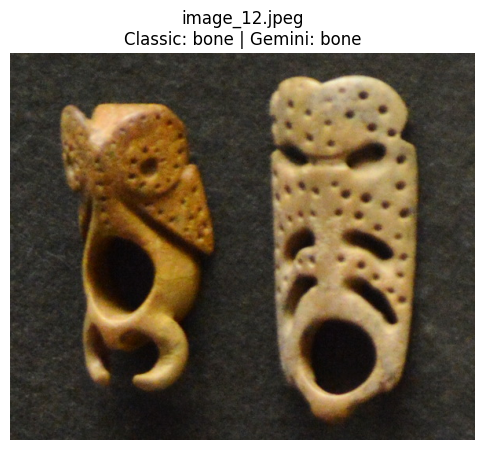

Processing 5/15: image_13.jpeg


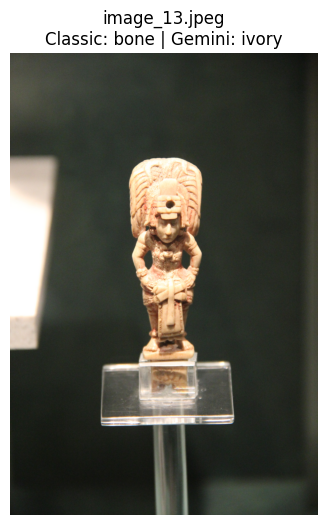

Processing 6/15: image_14.jpg


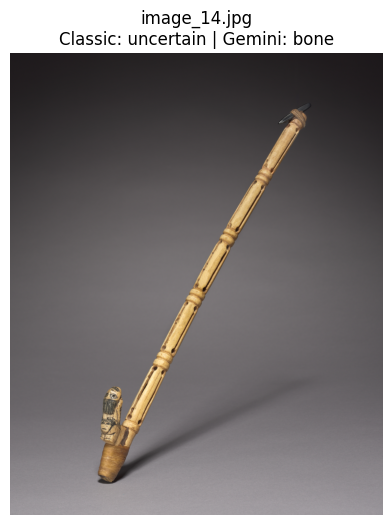

Processing 7/15: image_15.jpg


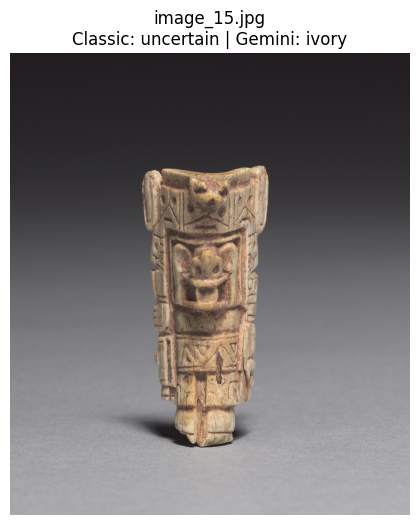

Processing 8/15: image_16.jpg


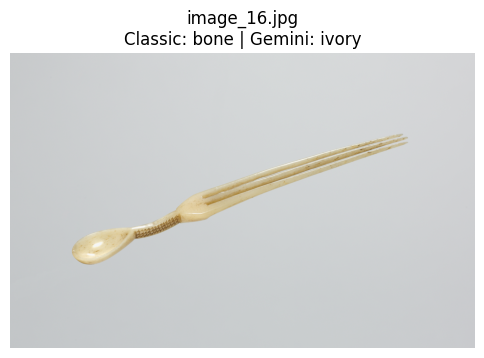

Processing 9/15: image_17.jpg


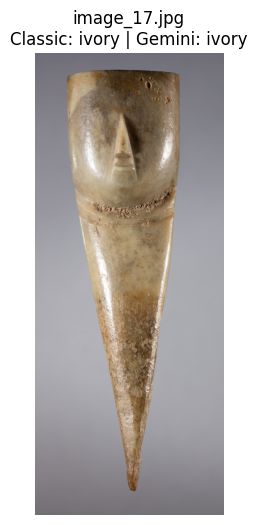

Processing 10/15: image_18.jpeg


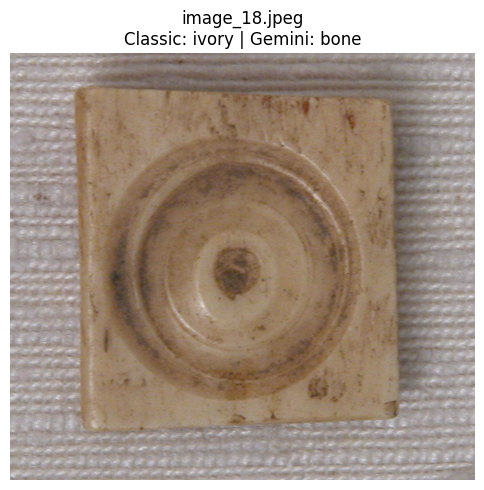

Processing 11/15: image_19.jpeg


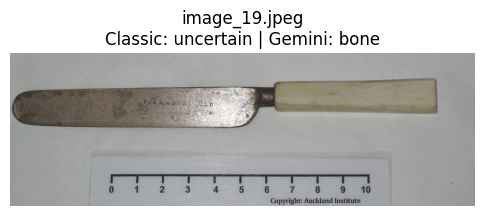

Processing 12/15: image_2.jpeg


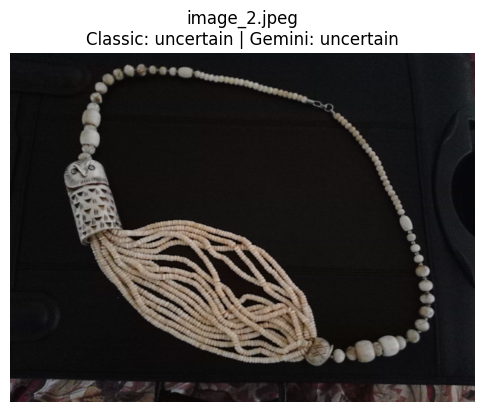

Processing 13/15: image_20.jpeg


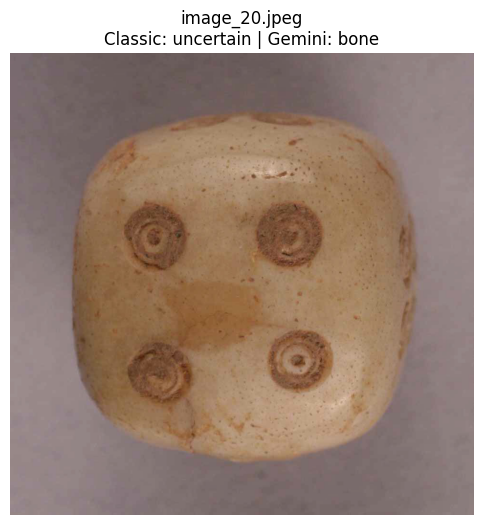

Processing 14/15: image_21.jpg


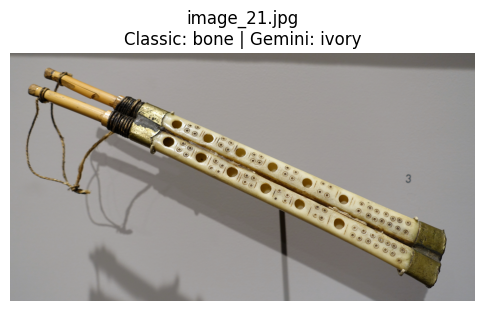

Processing 15/15: image_22.jpeg


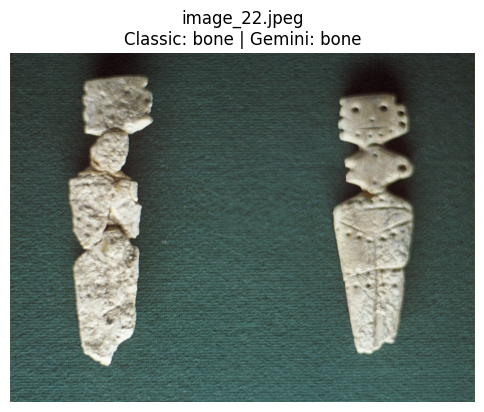

        filename  \
0   image_1.jpeg   
1  image_10.jpeg   
2  image_11.jpeg   
3  image_12.jpeg   
4  image_13.jpeg   

                                                                                                             path  \
0   /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/bone_gemini/image_1.jpeg   
1  /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/bone_gemini/image_10.jpeg   
2  /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/bone_gemini/image_11.jpeg   
3  /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/bone_gemini/image_12.jpeg   
4  /mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/bone_gemini/image_13.jpeg   

  classic_class  classic_ivory_frac  classic_avg_pred gemini_class  \
0          bone            0.051171         -0.852045    uncertain   
1         ivory            0.660127 

In [9]:
# Collect bone test images
image_files_bone = get_image_files(test_path_bone)
image_files_bone = image_files_bone[:15]   # limit for a quick run

print(f"Running comparison on {len(image_files_bone)} bone images...")

comparison_df_bone = compare_classic_vs_gemini(
    learn=learn,
    client=gemini_client,
    model_id=model_id,
    image_paths=image_files_bone,
    thr=0.3,
    show_examples=True,
)

bone_csv = outpath / "classic_vs_gemini_bone_comparison.csv"
comparison_df_bone.to_csv(bone_csv, index=False)

print(comparison_df_bone.head())
print(f"\nSaved comparison to:\n{bone_csv}")